<a href="https://colab.research.google.com/github/AdnanBz/TP-BIG-DATA/blob/TPs/TP02_BIG_DATA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install pandas dask[complete] psutil matplotlib pyarrow

In [ ]:

import os
import shutil
import time

import numpy as np
import pandas as pd

# ---------------- settings ----------------
FILE_NAME = "large_dataset_5gb.csv"
TARGET_GB = 5
CHUNK_ROWS = 2_000_000      # rows generated per step (~200 MB of text)
NUM_COLS = 5
SEED = 42
# ------------------------------------------

target_bytes = int(TARGET_GB * 1024 ** 3)
columns = [f"feature_{i + 1}" for i in range(NUM_COLS)]

# check free disk space first
free = shutil.disk_usage(os.path.dirname(os.path.abspath(FILE_NAME))).free
if free < target_bytes * 1.1:
    raise SystemExit(
        f"Not enough disk space: {free / 1024 ** 3:.1f} GB free, "
        f"{TARGET_GB * 1.1:.1f} GB needed."
    )

if os.path.exists(FILE_NAME):
    os.remove(FILE_NAME)

rng = np.random.default_rng(SEED)
rows_written = 0
start = time.time()
first = True

print(f"Generating ~{TARGET_GB} GB into {FILE_NAME} ...")
while True:
    size = os.path.getsize(FILE_NAME) if os.path.exists(FILE_NAME) else 0
    if size >= target_bytes:
        break

    df = pd.DataFrame(rng.standard_normal((CHUNK_ROWS, NUM_COLS)), columns=columns)
    df.to_csv(FILE_NAME, mode="w" if first else "a", header=first, index=False)
    first = False
    rows_written += CHUNK_ROWS

    size = os.path.getsize(FILE_NAME)
    elapsed = time.time() - start
    print(
        f"\r{size / 1024 ** 3:5.2f} GB / {TARGET_GB} GB | "
        f"{rows_written:,} rows | {elapsed:6.1f}s",
        end="",
        flush=True,
    )

final_size = os.path.getsize(FILE_NAME)
print(f"\nDone. File: {FILE_NAME}")
print(f"Size: {final_size / 1024 ** 3:.2f} GB | Rows: {rows_written:,} | "
      f"Time: {time.time() - start:.0f}s")

Generating ~5 GB into large_dataset_5gb.csv ...
 5.12 GB / 5 GB | 56,000,000 rows |  432.3s
Done. File: large_dataset_5gb.csv
Size: 5.12 GB | Rows: 56,000,000 | Time: 432s


In [ ]:
# ===== الخلية 1: الإعدادات + أداة القياس + تجربة Pandas العادي =====
import os, sys, json, subprocess

FILE = "large_dataset_5gb.csv"   # اسم الملف
USECOLS = "all"                  # "all" = كل الأعمدة | "feature_1" = عمود واحد
N_RUNS = 3                       # عدد مرات التكرار

print(f"حجم الملف: {os.path.getsize(FILE) / 1024**3:.2f} GB")

# ---- كود القياس: يُحفظ في ملف ويُشغَّل في عملية مستقلة لكل تجربة ----
WORKER = r'''
import sys, json, time, resource, psutil
import pandas as pd

method, path, usecols = sys.argv[1], sys.argv[2], sys.argv[3]
usecols = None if usecols == "all" else usecols.split(",")

base = psutil.Process().memory_info().rss / 1024**2   # الذاكرة قبل القراءة
start = time.time()

if method == "pandas":                        # قراءة الملف كاملاً
    df = pd.read_csv(path, usecols=usecols)
    mean, rows = df["feature_1"].mean(), len(df)

elif method == "chunking":                    # قراءة على دفعات
    total, rows = 0, 0
    for chunk in pd.read_csv(path, usecols=usecols, chunksize=1_000_000):
        total += chunk["feature_1"].sum()
        rows += len(chunk)
    mean = total / rows

elif method == "dask":                        # Dask
    import dask, dask.dataframe as dd
    ddf = dd.read_csv(path, usecols=usecols, blocksize="128MB")
    mean, rows = dask.compute(ddf["feature_1"].mean(), ddf["feature_1"].count())

seconds = time.time() - start
peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024   # أعلى ذاكرة (MB)

print(json.dumps({"time": seconds, "peak_mb": peak, "base_mb": base,
                  "extra_mb": peak - base, "mean": float(mean), "rows": int(rows)}))
'''
open("bench_worker.py", "w").write(WORKER)


# ---- دالة تشغيل الطريقة عدة مرات وحفظ النتائج ----
def run_benchmark(method, label):
    runs, status = [], "ok"
    for i in range(N_RUNS):
        p = subprocess.run([sys.executable, "bench_worker.py", method, FILE, USECOLS],
                           capture_output=True, text=True)
        if p.returncode != 0:                 # فشل (غالباً نفدت الذاكرة)
            status = f"failed (exit code {p.returncode}) - غالباً نفدت الذاكرة"
            print(f"[{label}] المحاولة {i+1}: فشلت ({status})")
            break
        r = json.loads(p.stdout.splitlines()[-1])
        runs.append(r)
        print(f"[{label}] المحاولة {i+1}: {r['time']:.1f} ث | ذروة الذاكرة {r['peak_mb']:.0f} MB "
              f"| فوق الأساس {r['extra_mb']:.0f} MB | المتوسط {r['mean']:.6f} | الأسطر {r['rows']:,}")
    json.dump({"method": method, "label": label, "status": status, "runs": runs},
              open(f"results_{method}.json", "w"))


# ---- تشغيل Pandas العادي ----
print("\n--- Standard Pandas (قراءة كاملة) ---")
run_benchmark("pandas", "Standard Pandas")

حجم الملف: 5.12 GB

--- Standard Pandas (قراءة كاملة) ---
[Standard Pandas] المحاولة 1: 41.7 ث | ذروة الذاكرة 4589 MB | فوق الأساس 4491 MB | المتوسط 0.000001 | الأسطر 56,000,000
[Standard Pandas] المحاولة 2: 38.8 ث | ذروة الذاكرة 4588 MB | فوق الأساس 4490 MB | المتوسط 0.000001 | الأسطر 56,000,000
[Standard Pandas] المحاولة 3: 39.6 ث | ذروة الذاكرة 4588 MB | فوق الأساس 4491 MB | المتوسط 0.000001 | الأسطر 56,000,000


In [ ]:

# ===== الخلية 2: Pandas Chunking (القراءة على دفعات بحجم مليون سطر) =====
# تعتمد على الخلية 1 (دالة run_benchmark والمتغيرات FILE وUSECOLS وN_RUNS)
print("--- Pandas Chunking ---")
_ = run_benchmark("chunking", "Pandas Chunking")


--- Pandas Chunking ---
[Pandas Chunking] المحاولة 1: 39.3 ث | ذروة الذاكرة 1808 MB | فوق الأساس 1710 MB | المتوسط 0.000001 | الأسطر 56,000,000
[Pandas Chunking] المحاولة 2: 39.1 ث | ذروة الذاكرة 1808 MB | فوق الأساس 1710 MB | المتوسط 0.000001 | الأسطر 56,000,000
[Pandas Chunking] المحاولة 3: 38.4 ث | ذروة الذاكرة 1808 MB | فوق الأساس 1710 MB | المتوسط 0.000001 | الأسطر 56,000,000


In [ ]:
# ===== الخلية 3: Dask DataFrame (حساب كسول وكتل بحجم 128MB) =====
# تعتمد على الخلية 1 (دالة run_benchmark والمتغيرات FILE وUSECOLS وN_RUNS)
print("--- Dask DataFrame ---")
_ = run_benchmark("dask", "Dask DataFrame")


--- Dask DataFrame ---
[Dask DataFrame] المحاولة 1: 37.2 ث | ذروة الذاكرة 1808 MB | فوق الأساس 1652 MB | المتوسط 0.000001 | الأسطر 56,000,000
[Dask DataFrame] المحاولة 2: 38.5 ث | ذروة الذاكرة 1808 MB | فوق الأساس 1651 MB | المتوسط 0.000001 | الأسطر 56,000,000
[Dask DataFrame] المحاولة 3: 38.9 ث | ذروة الذاكرة 1808 MB | فوق الأساس 1652 MB | المتوسط 0.000001 | الأسطر 56,000,000


=== جدول المقارنة (قياسات حقيقية، كل تجربة في عملية مستقلة) ===


,Method,Status,Time (s) mean,Time std,Peak RAM (MB),Extra RAM (MB),Mean feature_1,Rows
0,Standard Pandas,ok,40.03,1.20,4588,4491,0.000001,"56,000,000"
1,Pandas Chunking,ok,38.94,0.37,1808,1710,0.000001,"56,000,000"
2,Dask DataFrame,ok,38.22,0.74,1808,1652,0.000001,"56,000,000"



تطابق المتوسطات بين الطرق: نعم (أكبر فرق = 8.51e-20)


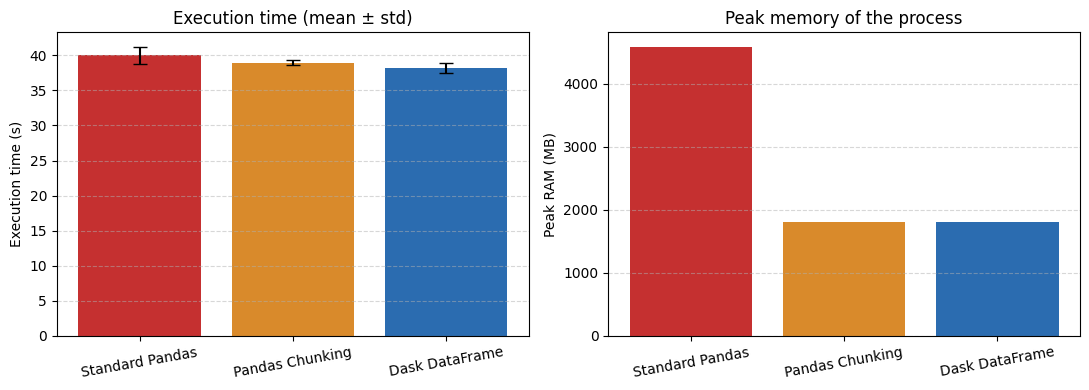


=== الاستنتاج ===
الأسرع: Dask DataFrame (38.2 ث)
الأقل استهلاكاً للذاكرة (الذروة): Pandas Chunking (1808 MB)
Dask مقابل Chunking: أسرع بنسبة 1.8%
ذروة ذاكرة Pandas العادي = 2.5 × ذروة Pandas Chunking


In [ ]:
# ===== الخلية 4: المقارنة النهائية (جدول + رسوم + استنتاج تلقائي) =====
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

METHODS = [("pandas", "Standard Pandas"), ("chunking", "Pandas Chunking"), ("dask", "Dask DataFrame")]
COLORS = {"Standard Pandas": "#c53030", "Pandas Chunking": "#d98a2b", "Dask DataFrame": "#2b6cb0"}

rows, ok = [], {}
for key, label in METHODS:
    path = f"results_{key}.json"
    if not os.path.exists(path):
        print(f"تنبيه: {path} غير موجود - شغّل خليته أولاً")
        continue
    res = json.load(open(path))
    runs = res["runs"]
    if runs and res["status"] == "ok":
        t = np.array([r["time"] for r in runs])
        peak = np.array([r["peak_mb"] for r in runs])
        extra = np.array([r["extra_mb"] for r in runs])
        ok[label] = {"t": t, "peak": peak, "extra": extra, "mean": runs[0]["mean"], "rows": runs[0]["rows"]}
        rows.append({"Method": label, "Status": "ok",
                     "Time (s) mean": round(t.mean(), 2), "Time std": round(t.std(), 2),
                     "Peak RAM (MB)": round(peak.mean()), "Extra RAM (MB)": round(extra.mean()),
                     "Mean feature_1": f"{runs[0]['mean']:.6f}", "Rows": f"{runs[0]['rows']:,}"})
    else:
        rows.append({"Method": label, "Status": res["status"], "Time (s) mean": None, "Time std": None,
                     "Peak RAM (MB)": None, "Extra RAM (MB)": None, "Mean feature_1": None, "Rows": None})

table = pd.DataFrame(rows)
print("=== جدول المقارنة (قياسات حقيقية، كل تجربة في عملية مستقلة) ===")
display(table)

# التحقق من تطابق النتائج بين الطرق الناجحة
if len(ok) > 1:
    means = [v["mean"] for v in ok.values()]
    same = max(means) - min(means) < 1e-6
    print(f"\nتطابق المتوسطات بين الطرق: {'نعم' if same else 'لا - راجع الكود'} "
          f"(أكبر فرق = {max(means) - min(means):.2e})")

# الرسوم البيانية
if ok:
    names = list(ok.keys())
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    cols = [COLORS[n] for n in names]
    ax[0].bar(names, [ok[n]["t"].mean() for n in names], yerr=[ok[n]["t"].std() for n in names],
              color=cols, capsize=5)
    ax[0].set_ylabel("Execution time (s)")
    ax[0].set_title("Execution time (mean ± std)")
    ax[1].bar(names, [ok[n]["peak"].mean() for n in names], color=cols)
    ax[1].set_ylabel("Peak RAM (MB)")
    ax[1].set_title("Peak memory of the process")
    for a in ax:
        a.grid(axis="y", linestyle="--", alpha=0.5)
        a.tick_params(axis="x", rotation=10)
    plt.tight_layout()
    plt.show()

    # الاستنتاج التلقائي
    fastest = min(names, key=lambda n: ok[n]["t"].mean())
    leanest = min(names, key=lambda n: ok[n]["peak"].mean())
    print("\n=== الاستنتاج ===")
    print(f"الأسرع: {fastest} ({ok[fastest]['t'].mean():.1f} ث)")
    print(f"الأقل استهلاكاً للذاكرة (الذروة): {leanest} ({ok[leanest]['peak'].mean():.0f} MB)")
    if "Pandas Chunking" in ok and "Dask DataFrame" in ok:
        tc, td = ok["Pandas Chunking"]["t"].mean(), ok["Dask DataFrame"]["t"].mean()
        print(f"Dask مقابل Chunking: {'أسرع' if td < tc else 'أبطأ'} بنسبة {abs(tc - td) / tc * 100:.1f}%")
    if "Standard Pandas" in ok and ("Pandas Chunking" in ok or "Dask DataFrame" in ok):
        other = min([n for n in names if n != "Standard Pandas"], key=lambda n: ok[n]["peak"].mean())
        ratio = ok["Standard Pandas"]["peak"].mean() / ok[other]["peak"].mean()
        print(f"ذروة ذاكرة Pandas العادي = {ratio:.1f} × ذروة {other}")
for label in [r["Method"] for r in rows if r["Status"] != "ok"]:
    print(f"\n{label}: لم تنجح التجربة - هذا هو الدليل الحقيقي على نفاد الذاكرة")
